# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohamedkhaled600/flyrank-internship-ml/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

***Answer:***

**Question:** which content pages should an editor review first?

**Decision and action:** an editor has a few review hours and thousands of pages; they work down a ranked queue and read the pages near the top. **Cost of a wrong pick:** wasted editor time, or a page that keeps losing clicks unnoticed.

**Real FlyRank problem this comes from:** FlyRank monitors large volumes of published content and already flags pages for refresh or click-through fixes with hand-written rules. This case study asks whether a model that sees only first-half-of-month signals can rank pages by how likely their clicks are to fall in the second half, and how much of its apparent skill survives honest validation. The deployed paper's abstract and introduction tell this same story.

In [1]:
import os, json
# Colab starts in /content, not inside the repo -- clone once, then work from work/notebooks
if not os.path.exists("../outputs/w07_playbook_metrics.json"):
    !git clone --quiet https://github.com/mohamedkhaled600/flyrank-internship-ml.git
    %cd flyrank-internship-ml/work/notebooks

metrics = json.load(open("../outputs/w07_playbook_metrics.json"))
print("Lane: content refresh / opportunity scoring")
print("Question: which pages should an editor review first?")
print("Label: declining = clicks in 16-31 March < clicks in 1-15 March (month =", metrics["month"] + ")")


Lane: content refresh / opportunity scoring
Question: which pages should an editor review first?
Label: declining = clicks in 16-31 March < clicks in 1-15 March (month = 2026-03)


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

***Answer:***

**Release / tables:** FlyRank ML Internship warehouse (gated Hugging Face dataset): `fact_content_daily_performance` (one row = report date x client x page; grain verified), `dim_content` (static attributes), `dim_clients` (inspected only).

**Windows:** development month March 2026 (mid-panel): 9,841,378 daily rows, 55 clients, 331,437 pages. Features from 1-15 March, label from 16-31 March. The final month (June 2026) was kept sealed and never used.

**Modelling panel:** 313,270 pages across 50 clients after requiring activity in both half-months and excluding deleted pages; 9.3% labelled declining.

**Excluded, and why:** GA4 columns (4.2% coverage); deleted pages (no action possible); AI-referrer breakdowns (out of scope); `days_since_update` (88.1% of pages have an update date after the cut-off, because `dim_content` stores only the latest date); pseudonymous IDs as features. No client names, page addresses or queries appear anywhere.

In [2]:
import pandas as pd
# Month-slice facts below were measured in w03_data_contract; panel facts come from the metrics JSON.
facts = pd.DataFrame([
    ("month used", metrics["month"]),
    ("daily rows in the month slice", "9,841,378"),
    ("clients / pages in the month slice", "55 / 331,437"),
    ("modelling panel (pages)", f"{metrics['n_rows_in_panel']:,}"),
    ("clients in the modelling panel", metrics["n_clients_in_panel"]),
    ("share labelled declining", metrics["base_rate"]),
    ("GA4 coverage this month", metrics["ga4_coverage_this_month"]),
], columns=["item", "value"])
facts


,item,value
0,month used,2026-03
1,daily rows in the month slice,"9,841,378"
2,clients / pages in the month slice,"55 / 331,437"
3,modelling panel (pages),"313,270"
4,clients in the modelling panel,50
5,share labelled declining,0.093
6,GA4 coverage this month,0.042


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

***Answer:***

**Unit and label:** one row = one page in March 2026; `declining` = second-half clicks < first-half clicks.

**Features (11):** first-half impressions, first-half average position, page age, word count, search volume, backlinks, category count, has-keyword-data flag, content type, intent, competition level. All known by 15 March or fixed page attributes.

**Baseline:** hand-written rule - stale (91+ days) AND visible AND click-through rate below its position band's average; score = impressions. Signal checks: CTR falls with position (CONFIRMED: 0.93% / 0.47% / 0.33% / 0.21% across the four bands); staleness OPPOSITE among the ~12% of pages with a valid update date.

**Models:** Logistic Regression (standardised) and Random Forest (300 trees, depth 8, seed 42).

**Validation:** `GroupShuffleSplit` by client, 80/20: 40 train clients (270,159 pages), 10 test clients (43,111 pages), zero overlap. Metrics: precision@K and AUC, next to the base rate (10.6% in test).

**Leakage checks:** timeline (last feature date 15 March < first label date 16 March); label-adjacent features removed (`prior_clicks_h1`, `prior_ctr_h1`); invalid date field removed (`days_since_update_h1_end`); random-vs-grouped comparison; permutation importance scored on AUC; no product-flag columns exist.

In [3]:
print("Split design:", metrics["split_design"])
print("Model:", metrics["model"])
print()
print("Features used:")
for f in metrics["feature_set"]:
    print("  -", f)
print()
print("Deliberately excluded (leakage-prone):", metrics["excluded_leakage_suspects"])


Split design: GroupShuffleSplit by client_hash_id, test_size=0.2, seed=42
Model: RandomForestClassifier(n_estimators=300, max_depth=8)

Features used:
  - prior_impressions_h1
  - prior_avg_position_h1
  - content_age_days_h1_end
  - word_count
  - search_volume
  - backlinks
  - category_count
  - has_keyword_data
  - content_type
  - main_intent
  - competition_level

Deliberately excluded (leakage-prone): ['prior_clicks_h1', 'prior_ctr_h1', 'days_since_update_h1_end']


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

***Answer:***

On held-out clients the Random Forest ranked pages better than the baseline rule at the top of the queue and overall (AUC 0.862 vs the rule's uninformative 0.500, because the rule scores most pages zero). Precision at small K is noisy (a re-run gave 0.40 / 0.45 / 0.36 at K = 10 / 20 / 50 with identical AUC), so read top-of-queue numbers as roughly +/-0.1.

**Leakage before/after:** removing label-adjacent features and the invalid date field cut Random Forest AUC from 0.956 to 0.862 and Logistic Regression from 0.911 to 0.675.

**Split design:** the same honest Random Forest scored AUC 0.915 under a random row split and 0.862 under the client-grouped split, but precision@10 fell from 0.70 to 0.40.

**Interpretation:** first-half impressions dominate permutation importance (0.2008), then average position (0.0212). Impressions are correlated with the removed click features, so some of that importance may be a diluted echo of how the label is built (not separately tested). Misses were mostly low-visibility, deep-position pages; scores are compressed (max about 0.53), so the output is a ranking, not a calibrated probability.

Test-split base rate: 0.106


,model,precision@10,precision@20,precision@50,AUC
0,Baseline rule,0.2,0.20,0.24,0.500
1,Logistic Regression,0.3,0.25,0.36,0.675
2,Random Forest,0.5,0.50,0.32,0.862


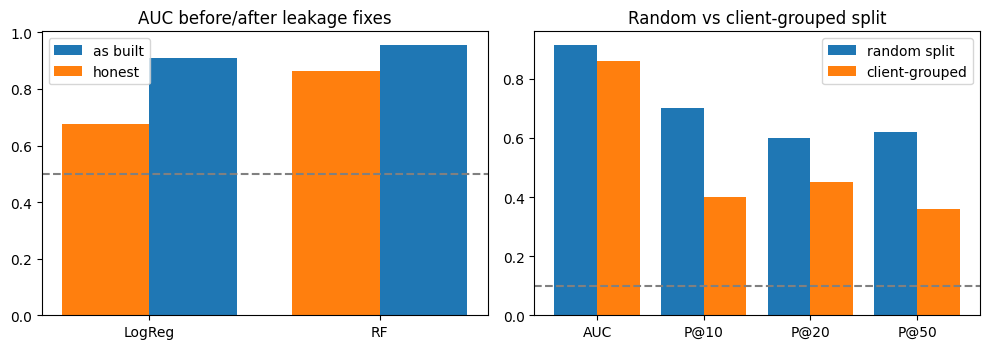

In [4]:
import matplotlib.pyplot as plt

# Values copied from the executed outputs of w05_model (client-grouped test split) and
# w06_validation_audit; re-run those notebooks to regenerate them.
table2 = pd.DataFrame({
    "model": ["Baseline rule", "Logistic Regression", "Random Forest"],
    "precision@10": [0.20, 0.30, 0.50],
    "precision@20": [0.20, 0.25, 0.50],
    "precision@50": [0.24, 0.36, 0.32],
    "AUC": [0.500, 0.675, 0.862],
})
print("Test-split base rate: 0.106")
display(table2)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(["LogReg", "RF"], [0.911, 0.956], width=0.38, align="edge", label="as built")
axes[0].bar(["LogReg", "RF"], [0.675, 0.862], width=-0.38, align="edge", label="honest")
axes[0].axhline(0.5, ls="--", c="grey"); axes[0].set_title("AUC before/after leakage fixes"); axes[0].legend()
labels = ["AUC", "P@10", "P@20", "P@50"]
rand, grp = [0.915, 0.70, 0.60, 0.62], [0.862, 0.40, 0.45, 0.36]
x = range(len(labels))
axes[1].bar([i - 0.2 for i in x], rand, width=0.4, label="random split")
axes[1].bar([i + 0.2 for i in x], grp, width=0.4, label="client-grouped")
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(labels)
axes[1].axhline(0.10, ls="--", c="grey"); axes[1].set_title("Random vs client-grouped split"); axes[1].legend()
plt.tight_layout(); plt.show()


## 5. Limitations

*What this work cannot claim.*

***Answer:***

- **One month, one portfolio.** Validated on March 2026 and 10 held-out clients; not checked on another month or a new client.
- **Search data only.** GA4 covered 4.2% of rows, so nothing here speaks to engagement or content quality.
- **Label construction.** A raw comparison of two counts carries floor and regression-to-the-mean effects; the second window (16 days) is one day longer than the first (15), tilting the label slightly toward "not declining". "Clicks fell" is not "needs a refresh".
- **Possible residual leak** through first-half impressions (not ablated).
- **Update dates are a current snapshot,** so staleness could not be modelled and the baseline's staleness rule covers only ~12% of pages.
- **Noisy at the top:** precision@10 moved by about 0.1 between runs.
- **Observational:** nothing here tests whether refreshing a page helps. Results are directional and decision-support only.

In [5]:
limits = pd.DataFrame([
    ("GA4 coverage (share of rows)", 0.042),
    ("pages with update date after cut-off (share)", 0.881),
    ("AUC, client-grouped vs random split", "0.862 vs 0.915"),
    ("precision@10 run-to-run spread", "0.40 - 0.50"),
    ("days in label windows (first / second half)", "15 / 16"),
], columns=["limitation", "measured value"])
limits


,limitation,measured value
0,GA4 coverage (share of rows),0.042
1,pages with update date after cut-off (share),0.881
2,"AUC, client-grouped vs random split",0.862 vs 0.915
3,precision@10 run-to-run spread,0.40 - 0.50
4,days in label windows (first / second half),15 / 16


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

***Answer:***

Ranked actions (March 2026 panel). Only rank 1 is backed by the validated ranking evidence; rank 2 is chosen by position band.

1. **review_for_refresh** (`high_risk_visible`, `high_risk_despite_position`) - highest model scores; read the page, check for business context.
2. **quick_win_optimize** (`striking_distance_opportunity`) - average position 10-20.
3. **protect** (`top_performer_low_risk`) - leave alone, confirm nothing is broken.
4. **monitor** (`high_risk_low_signal`) - revisit next month.
5. **no_action** (`low_value_low_risk`) - low risk, low visibility.

**Human review before acting:** read the page; check for removal/merge plans; look for seasonal/legal/campaign context; spot-check rows outside the top.
**Never automate:** publishing or editing from the queue; deleting or de-indexing `no_action` pages; applying the queue to unvalidated clients or months.
**Monitoring / retrain triggers:** top-of-queue precision drifting toward baseline; base rate far from ~10%; GA4 coverage rising materially; page or client mix shifting.
**Cost/value:** the cost of a wrong pick is editor time; a click-value tiebreaker (clicks x cost per click) is a sensible next step but was not computed.

In [6]:
ad = pd.Series(metrics["action_distribution"])
dist = pd.DataFrame({"pages": ad, "share_%": (100 * ad / ad.sum()).round(1)})
dist.loc["TOTAL"] = [ad.sum(), 100.0]
dist


,pages,share_%
no_action,156612.0,50.0
protect,63449.0,20.3
review_for_refresh,61050.0,19.5
quick_win_optimize,26906.0,8.6
monitor,5253.0,1.7
TOTAL,313270.0,100.0


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

***Answer:***

The deployed paper (`docs/index.html`) is a single self-contained page. Its four charts are inline SVG built from the numbers above and from `work/outputs/w07_playbook_metrics.json`; the committed figure `work/figures/w07_action_distribution.png` shows the same action split as the paper's Figure 4.

| Paper element | Source |
|---|---|
| Figure 1 (leakage before/after) | w05_model, honest vs as-built tables |
| Figure 2 (random vs grouped split) | w06_validation_audit, section 2 |
| Figure 3 (permutation importance) | w05_model, section 4 |
| Figure 4 (action distribution) | w07_playbook_metrics.json |
| Tables 2-3 | w05_model, w07_action_playbook |

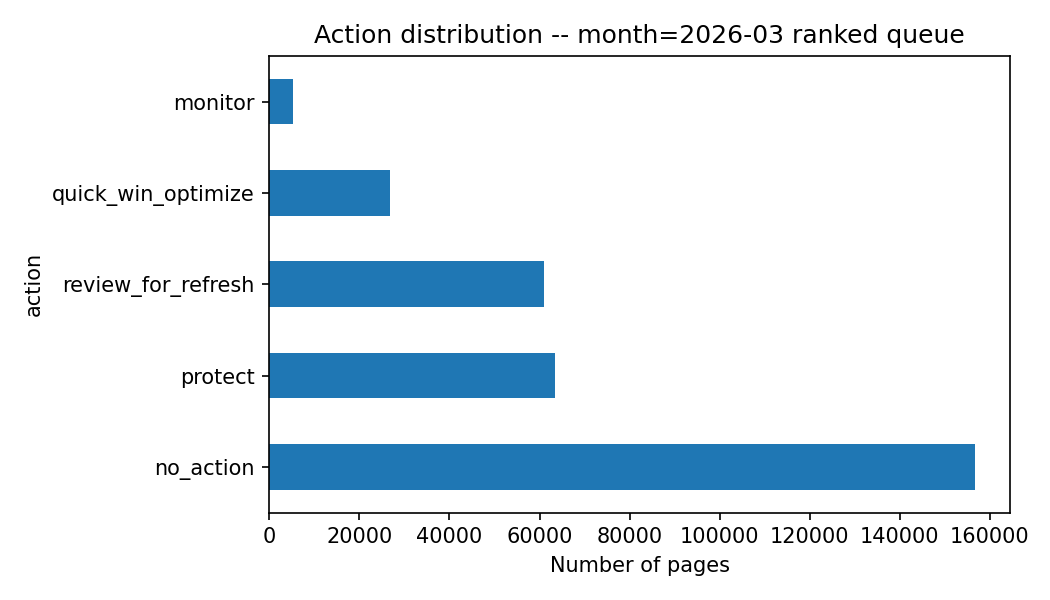

Metrics JSON: ['w07_playbook_metrics.json']


In [7]:
from IPython.display import Image, display
display(Image(filename="../figures/w07_action_distribution.png"))
print("Metrics JSON:", sorted(os.listdir("../outputs")))


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.


## ML-12 — 5-minute demo outline

*Optional for the Week-8 showcase. Five beats, about 5 minutes.*

| Time | Beat | What I say |
|---|---|---|
| 0:00-0:45 | **Question** | An editor has a few review hours and thousands of pages. Which pages should they look at first? The action is a human review; a wrong pick costs wasted hours, or a page that keeps losing clicks unnoticed. |
| 0:45-1:45 | **Method** | Real search-performance data from FlyRank's warehouse, March 2026, about 313k pages across 50 clients. Features come only from the first half of the month; the label ("clicks fell in the second half") only from the second. A rule baseline first, then a Random Forest, validated by splitting on client, not on row. |
| 1:45-2:45 | **One chart** | The action split (paper Figure 4 / `work/figures/w07_action_distribution.png`). Takeaway: about half of pages have no impressions at all in the window, so most of the panel is correctly "no action". |
| 2:45-4:00 | **One honest result** | My first model scored AUC 0.956, the warning sign: one feature was one side of the label's own comparison, and a date field was invalid for 88% of rows. With both removed, AUC on held-out clients was 0.862 (base rate about 10%). A random split looked better (0.915), and top-10 precision fell from 0.70 to 0.40 when I split by client, so I report the grouped number. |
| 4:00-5:00 | **One recommendation** | Use the queue as a review list, not an autopilot: read the top pages in each action group and check for business context the data cannot see. Never auto-edit, auto-publish or auto-delete from it. Re-check monthly; retrain if top-of-queue precision or the base rate drifts. |

**If asked:** precision@10 moves a lot between runs (each row is 10 points), so AUC 0.862 is the stable headline: identical across three runs. Limits: one month, search data only (GA4 4.2%), directional and decision-support, not causal.

## ML-12 — Two shareable cuts

### Social post (methodology)

My first model scored 0.956 AUC. That's when I got suspicious.

I was predicting which web pages lose search clicks, using real content data (about 313k pages, one month). The "declining" label compared clicks across two half-months, and my top feature was literally one side of that comparison. I removed it, plus a date field that was invalid for 88% of rows, and AUC fell to 0.862 on held-out clients.

Then I split by client instead of by row, and top-of-queue precision dropped even further (0.70 to 0.40).

A score that looks too good is a question, not a result. Paper and notebooks: https://mohamedkhaled600.github.io/flyrank-internship-ml/

### Employer-facing summary (3 sentences)

I built a decision-support tool that ranks content pages for editor review, using a Random Forest trained on real search-performance data from FlyRank's warehouse (about 313k pages across 50 clients, March 2026). On held-out clients it separated pages whose clicks fell from those that didn't with AUC 0.862 (base rate about 10%) and stayed ahead of my rule-based baseline at the top of the ranked list, after I found and removed leakage-prone features that had inflated an earlier version to 0.956. I documented the limits plainly (single month, search data only, directional rather than causal) and turned the output into a human-reviewed action playbook with monitoring triggers.